# Baseline CNN with class-weighted training

This notebook trains a small baseline CNN on the preprocessed, pre-split images produced by `chest_xray_train_val_test_split.ipynb`. Run that preparation notebook first, including its duplicate-removal cell. The expected folder structure is `chest_xray_cnn_splits/{train,val,test}/{NORMAL,PNEUMONIA}`.

The class-weight calculation follows the inverse-frequency method in `imbalance.ipynb`: weights are computed from **training labels only** and passed to `model.fit(class_weight=...)`. Validation and test data remain unbalanced. The test set is evaluated only after training.

In [1]:
%pip install -q tensorflow kagglehub numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: c:\Users\apsur\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


## Find the prepared splits

This searches the current folder and the same KaggleHub cache location used by the preparation notebook. If the split folder is missing, run the preparation notebook first.

In [2]:
from pathlib import Path
import kagglehub
import numpy as np
import tensorflow as tf

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
DATASET_SLUG = "paultimothymooney/chest-xray-pneumonia"

download_dir = Path(kagglehub.dataset_download(DATASET_SLUG))
candidate_dirs = [
    Path.cwd() / "chest_xray_cnn_splits",
    Path.cwd().parent / "chest_xray_cnn_splits",
    download_dir.parent / "chest_xray_cnn_splits",
]
data_dir = next(
    (
        path
        for path in candidate_dirs
        if all((path / split).is_dir() for split in ("train", "val", "test"))
    ),
    None,
)
if data_dir is None:
    checked = "\n".join(str(path) for path in candidate_dirs)
    raise FileNotFoundError(
        "Could not find the prepared train/val/test folders. Run "
        "chest_xray_train_val_test_split.ipynb through its split and "
        f"duplicate-removal cells first. Checked:\n{checked}"
    )

print(f"Using prepared data from: {data_dir}")

c:\Users\apsur\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using prepared data from: C:\Users\apsur\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\chest_xray_cnn_splits


## Load train, validation, and test datasets

Folder names are converted to integer labels. The expected alphabetical label mapping is `NORMAL=0`, `PNEUMONIA=1`, matching `imbalance.ipynb`. Only the training dataset is shuffled.

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir / "train",
    image_size=IMAGE_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir / "val",
    image_size=IMAGE_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir / "test",
    image_size=IMAGE_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

class_names = train_ds.class_names
if class_names != ["NORMAL", "PNEUMONIA"]:
    raise ValueError(
        f"Unexpected class order {class_names}; expected ['NORMAL', 'PNEUMONIA']."
    )
if val_ds.class_names != class_names or test_ds.class_names != class_names:
    raise ValueError("Train, validation, and test folders must have matching classes.")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print("Class mapping:", {name: index for index, name in enumerate(class_names)})

Found 4688 files belonging to 2 classes.
Found 518 files belonging to 2 classes.
Found 618 files belonging to 2 classes.
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


## Compute class weights from training data

This uses the same inverse-frequency formula as `compute_class_weights` in `imbalance.ipynb`: `total_samples / (number_of_classes * class_count)`. These weights reweight each example's loss during training; no images are copied or removed here.

In [4]:
num_classes = len(class_names)
train_counts = np.zeros(num_classes, dtype=np.int64)
for _, labels in train_ds:
    train_counts += np.bincount(labels.numpy().reshape(-1), minlength=num_classes)

if np.any(train_counts == 0):
    missing_classes = [class_names[i] for i, count in enumerate(train_counts) if count == 0]
    raise ValueError(f"Cannot compute class weights; no training images for: {missing_classes}")

total_train_images = int(train_counts.sum())
class_weights = {
    class_id: float(total_train_images / (num_classes * count))
    for class_id, count in enumerate(train_counts)
}
print("Training image counts:")
for class_id, class_name in enumerate(class_names):
    print(f"  {class_name}: {train_counts[class_id]:,} images; weight={class_weights[class_id]:.4f}")

Training image counts:
  NORMAL: 1,213 images; weight=1.9324
  PNEUMONIA: 3,475 images; weight=0.6745


## Build and train a baseline CNN

The model uses grayscale 224×224 inputs, a few convolution and pooling blocks, and a two-class softmax output. `class_weights` is passed to `fit`; validation data is used for early stopping but is not class-weighted.

In [5]:
tf.keras.utils.set_random_seed(SEED)

model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(*IMAGE_SIZE, 1)),
        tf.keras.layers.Rescaling(1.0 / 255),
        tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(num_classes, activation="softmax"),
    ],
    name="baseline_cnn",
)
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[early_stopping],
)

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,058 (394.76 KB)

 Trainable params: 101,058 (394.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 71s 474ms/step - accuracy: 0.5433 - loss: 0.6513 - val_accuracy: 0.6409 - val_loss: 0.5849
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 71s 484ms/step - accuracy: 0.6913 - loss: 0.5313 - val_accuracy: 0.6680 - val_loss: 0.5131
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 75s 507ms/step - accuracy: 0.7875 - loss: 0.4174 - val_accuracy: 0.8822 - val_loss: 0.2811
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 91s 618ms/step - accuracy: 0.8633 - loss: 0.3041 - val_accuracy: 0.8726 - val_loss: 0.2888
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 81s 550ms/step - accuracy: 0.8786 - loss: 0.2711 - val_accuracy: 0.8687 - val_loss: 0.3055
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 71s 480ms/step - accuracy: 0.8831 - loss: 0.2612 - val_accuracy: 0.8745 - val_loss: 0.2804
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 80s 540ms/step - accuracy: 0.8919 - loss: 0.2531 - val_accuracy: 0.8282 - val_loss: 0.4807
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 78s 525ms/step - accuracy: 0.8938 - loss: 0

In [ ]:
from pathlib import Path

model_path = Path.cwd() / "baseline_cnn_class_weighted.keras"
model.save(model_path)
if not model_path.is_file() or model_path.stat().st_size == 0:
    raise IOError(f"Model save did not create a non-empty file: {model_path}")
print(f"Full Keras model saved to: {model_path.resolve()}")

## Evaluate once on the held-out test set

The test set was not used to compute class weights or select model checkpoints.

In [6]:
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_true = np.concatenate([labels.numpy().reshape(-1) for _, labels in test_ds])
probabilities = model.predict(test_ds, verbose=0)
y_pred = np.argmax(probabilities, axis=1)
print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))
print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true, y_pred))

Test loss: 0.5102
Test accuracy: 0.7735

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.7862    0.5411    0.6410       231
   PNEUMONIA     0.7691    0.9121    0.8345       387

    accuracy                         0.7735       618
   macro avg     0.7776    0.7266    0.7378       618
weighted avg     0.7755    0.7735    0.7622       618

Confusion matrix (rows=true, columns=predicted):
[[125 106]
 [ 34 353]]


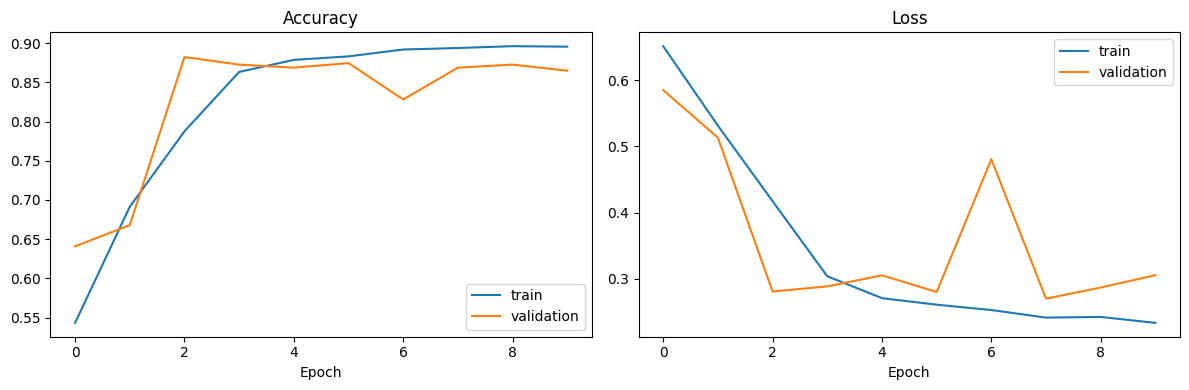

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()